# Solar filament segmentation: full pipeline

Data, folds, training, weights, test inference, validation and a fold-0
evaluation. Steps that need a GPU or the trained weights are switched by the
flags in the next cell.

```
H-alpha image -> 7 YOLO11 detectors -> candidates
  -> 5 U-Nets segment each candidate
  -> gradient boosting ranks the candidates, keeps as many as the 5-of-7 vote
  -> extent-robust U-Nets draw the final masks -> non-overlapping painting -> submission.csv
```

In [1]:
import glob
import os
import sys
import time
from pathlib import Path

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO))

RUN_TRAINING = False        # trains all 17 models (~17 GPU hours on a P100)
RUN_INFERENCE = True        # test-set submission (two candidate pools, ~2 h on a T4); skipped without weights
RUN_FOLD0_EVAL = True       # fold-0 single-model PQ; skipped without weights
FOLD0_IMAGES = None         # None = the whole fold; a small number gives a quick, noisy look on CPU
WEIGHTS = REPO / "weights"

# On Kaggle the competition data is mounted under /kaggle/input
if "MAGFILO_DIR" not in os.environ:
    hits = glob.glob("/kaggle/input/**/MAGFiLO_1.0_Kaggle_2026", recursive=True)
    if hits:
        os.environ["MAGFILO_DIR"] = hits[0]

## 1. Environment

In [2]:
import importlib.metadata as md

import torch

from filament.data import TEST_IMAGES, TRAIN_IMAGES, data_root

print("python", sys.version.split()[0])
for pkg in ["torch", "torchvision", "ultralytics", "segmentation-models-pytorch", "timm",
            "pycocotools", "opencv-python", "opencv-python-headless", "numpy", "pandas"]:
    try:
        print(f"{pkg:30s} {md.version(pkg)}")
    except md.PackageNotFoundError:
        print(f"{pkg:30s} -")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", torch.cuda.get_device_name() if DEVICE.type == "cuda" else "cpu")
print("data root:", data_root(), "exists:", data_root().exists())

python 3.13.16
torch                          2.11.0+cu130
torchvision                    0.26.0+cu130
ultralytics                    8.4.173
segmentation-models-pytorch    0.5.0
timm                           1.0.29
pycocotools                    2.0.11
opencv-python                  4.14.0.94
opencv-python-headless         4.14.0.94
numpy                          2.1.3
pandas                         2.2.3
device: Tesla T4
data root: /kaggle/input/competitions/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026 exists: True


## 2. Data

Each image has one to three annotator records, and the metric scores
predictions against each record.

In [3]:
from collections import Counter

import numpy as np

from filament.data import load_records

records = load_records()
stems = sorted({r.stem for r in records})
records_per_image = Counter(Counter(r.stem for r in records).values())
areas = np.array([f.area for r in records for f in r.filaments])
short_side = np.array([min(f.bbox[2], f.bbox[3]) for r in records for f in r.filaments])

print(f"{len(stems)} training images, {len(records)} records, {len(areas)} filaments")
print("records per image:", dict(sorted(records_per_image.items())))
print("filaments per record: median", int(np.median([len(r.filaments) for r in records])))
print(f"filament area: median {np.median(areas):.0f} px, 10-90 % range "
      f"{np.percentile(areas, 10):.0f}-{np.percentile(areas, 90):.0f} px of a 2048 x 2048 frame")
print("chirality categories:", dict(sorted(Counter(f.category_id for r in records for f in r.filaments).items())))
print("test images:", len(list((data_root() / TEST_IMAGES).glob("*.jpeg"))))

707 training images, 1154 records, 8199 filaments
records per image: {1: 411, 2: 145, 3: 151}
filaments per record: median 7
filament area: median 1228 px, 10-90 % range 410-4685 px of a 2048 x 2048 frame
chirality categories: {1: 2535, 2: 2590, 3: 3074}
test images: 180


### Annotator disagreement

One image labelled by three annotators (one colour per record).

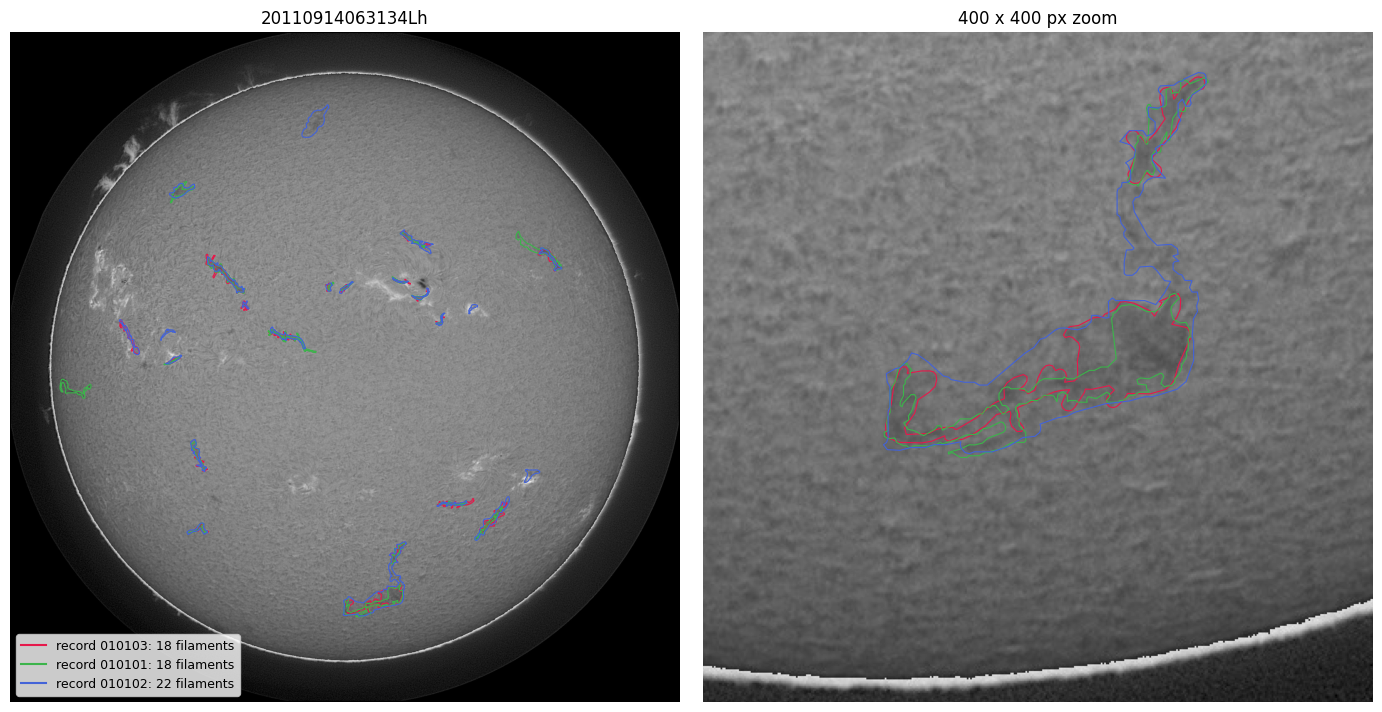

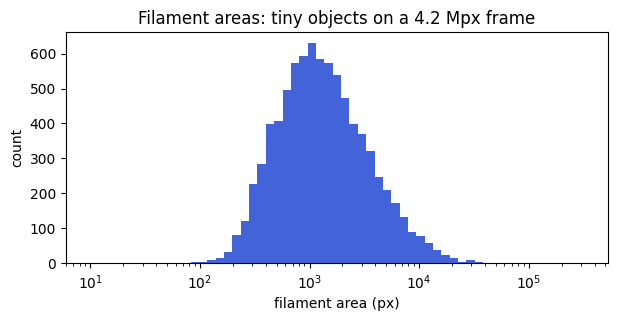

In [4]:
import matplotlib.pyplot as plt

from filament.data import load_image_gray

by_stem = {}
for r in records:
    by_stem.setdefault(r.stem, []).append(r)
stem = max((s for s in by_stem if len(by_stem[s]) == 3), key=lambda s: sum(len(r.filaments) for r in by_stem[s]))
img = load_image_gray(data_root() / TRAIN_IMAGES, stem + ".jpeg")
colors = ["#e6194b", "#3cb44b", "#4363d8"]

# zoom on the region where the first record's largest filament lies
big = max(by_stem[stem][0].filaments, key=lambda f: f.area)
cx, cy = big.bbox[0] + big.bbox[2] / 2, big.bbox[1] + big.bbox[3] / 2
x0, y0 = int(np.clip(cx - 200, 0, 1648)), int(np.clip(cy - 200, 0, 1648))

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, (xa, xb, ya, yb) in zip(axes, [(0, 2048, 0, 2048), (x0, x0 + 400, y0, y0 + 400)]):
    ax.imshow(img, cmap="gray")
    for color, rec in zip(colors, by_stem[stem]):
        for f in rec.filaments:
            poly = np.array(f.polygon).reshape(-1, 2)
            ax.plot(*np.vstack([poly, poly[:1]]).T, color=color, lw=0.8)
        ax.plot([], [], color=color, label=f"record {rec.record_id.split('-')[0]}: {len(rec.filaments)} filaments")
    ax.set_xlim(xa, xb)
    ax.set_ylim(yb, ya)
    ax.axis("off")
axes[0].legend(loc="lower left", fontsize=9)
axes[0].set_title(stem)
axes[1].set_title("400 x 400 px zoom")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 3))
plt.hist(areas, bins=np.logspace(1, 5.5, 60), color="#4363d8")
plt.xscale("log")
plt.xlabel("filament area (px)")
plt.ylabel("count")
plt.title("Filament areas: tiny objects on a 4.2 Mpx frame")
plt.show()

## 3. Cross-validation folds

Folds are grouped by observing day, since images from the same day are
nearly identical.

In [5]:
import json

from filament.data import FOLDS_PATH, split_stems

folds = split_stems(records, n_folds=5, seed=0)
committed = json.loads(FOLDS_PATH.read_text())["folds"]
assert [sorted(f) for f in folds] == committed, "fold split does not regenerate"
day_fold = {}
for k, fold in enumerate(folds):
    for s in fold:
        assert day_fold.setdefault(s[:8], k) == k, "a day straddles two folds"
for k, fold in enumerate(folds):
    recs = [r for r in records if r.stem in fold]
    print(f"fold {k}: {len(fold)} images, {len({s[:8] for s in fold})} days, {len(recs)} records, "
          f"{sum(len(r.filaments) for r in recs)} filaments")

fold 0: 142 images, 131 days, 227 records, 1634 filaments
fold 1: 142 images, 131 days, 233 records, 1687 filaments
fold 2: 141 images, 131 days, 236 records, 1568 filaments
fold 3: 141 images, 134 days, 228 records, 1582 filaments
fold 4: 141 images, 129 days, 230 records, 1728 filaments


## 4. Metric

`filament.metric` reproduces the competition's PQ. As a reference, one
annotator scored against the others on the multi-record images gets a PQ of
about 0.34.

In [6]:
from filament.data import gt_rows_for
from filament.metric import pq_from_rles

multi = [s for s in by_stem if len(by_stem[s]) > 1]
first = [by_stem[s][0] for s in multi]
others = [r for s in multi for r in by_stem[s][1:]]
human_pred = [(f"{r.stem}_{k}", rle) for r in first for k, (_, rle) in enumerate(gt_rows_for([r]), 1)]
res = pq_from_rles(gt_rows_for(others), human_pred)
print(f"one annotator vs the others on {len(multi)} multi-record images:",
      {k: round(v, 3) if isinstance(v, float) else v for k, v in res.items()})

one annotator vs the others on 296 multi-record images: {'pq': 0.34, 'tp': 1611, 'fp': 1400, 'fn': 1379, 'mean_iou_of_tps': 0.633, 'sq': 0.633, 'rq': 0.537}


## 5. Training

* 7 detectors: YOLO11s at 1280 px for each fold, plus YOLO11s at 1536 px and
  YOLO11m at 1280 px.
* 5 U-Nets (ResNet-34), one per fold, 12 epochs.
* 5 extent-robust U-Nets, trained on boxes that are too short or too long,
  48 epochs.

Set `RUN_TRAINING = True` to train everything (about 25 GPU hours).

In [7]:
from filament.detector import train_detector
from filament.refiner import train_refiner

DETECTOR_RUNS = [dict(fold=f, out=WEIGHTS / f"det_f{f}.pt") for f in range(5)] + [
    dict(fold=0, out=WEIGHTS / "det_s1536_f0.pt", imgsz=1536),
    dict(fold=0, out=WEIGHTS / "det_m1280_f0.pt", model="yolo11m.pt", batch=6),
]
REFINER_RUNS = [dict(fold=f, out=WEIGHTS / f"refiner_f{f}.pt") for f in range(5)] + [
    dict(fold=f, out=WEIGHTS / f"refiner_extent_f{f}.pt", extent_robust=True, epochs=48) for f in range(5)
]
if RUN_TRAINING:
    for kw in DETECTOR_RUNS:
        train_detector(work=REPO / "runs", **kw)
    for kw in REFINER_RUNS:
        train_refiner(**kw)
else:
    print("RUN_TRAINING is False; planned runs:")
    for kw in DETECTOR_RUNS:
        print("  detector", kw)
    for kw in REFINER_RUNS:
        print("  refiner ", kw)


RUN_TRAINING is False; planned runs:
  detector {'fold': 0, 'out': PosixPath('/kaggle/working/solar-filament-seg/weights/det_f0.pt')}
  detector {'fold': 1, 'out': PosixPath('/kaggle/working/solar-filament-seg/weights/det_f1.pt')}
  detector {'fold': 2, 'out': PosixPath('/kaggle/working/solar-filament-seg/weights/det_f2.pt')}
  detector {'fold': 3, 'out': PosixPath('/kaggle/working/solar-filament-seg/weights/det_f3.pt')}
  detector {'fold': 4, 'out': PosixPath('/kaggle/working/solar-filament-seg/weights/det_f4.pt')}
  detector {'fold': 0, 'out': PosixPath('/kaggle/working/solar-filament-seg/weights/det_s1536_f0.pt'), 'imgsz': 1536}
  detector {'fold': 0, 'out': PosixPath('/kaggle/working/solar-filament-seg/weights/det_m1280_f0.pt'), 'model': 'yolo11m.pt', 'batch': 6}
  refiner  {'fold': 0, 'out': PosixPath('/kaggle/working/solar-filament-seg/weights/refiner_f0.pt')}
  refiner  {'fold': 1, 'out': PosixPath('/kaggle/working/solar-filament-seg/weights/refiner_f1.pt')}
  refiner  {'fold': 

## 6. Weights

Missing weights are downloaded from the GitHub release and checked against
`data/weights.sha256`.

In [8]:
from filament.ensemble import DET_FILES, EXTENT_REFINER_FILES, REFINER_FILES
from filament.weights import WEIGHTS_URL, download, problems, read_manifest

ALL_WEIGHTS = DET_FILES + REFINER_FILES + EXTENT_REFINER_FILES
if problems(WEIGHTS, read_manifest()):
    try:
        download(WEIGHTS, WEIGHTS_URL)
    except SystemExit as e:  # the release may not be public yet; training (section 5) also produces these files
        print(e)
bad = problems(WEIGHTS, read_manifest())
print("weight problems:", bad or "none")


def missing_weights(names=ALL_WEIGHTS):
    return [n for n in names if not (WEIGHTS / n).exists()]

weight problems: none


## 7. Test inference

1. Candidate pool: detectors, grouping and U-Net masks.
2. Repaint: the same candidates with the extent-robust U-Nets' masks.
3. Selection: rank the candidates and keep as many as the 5-of-7 vote.
4. Paint the kept masks without overlap and remove small or low-contrast ones.

In [9]:
import pandas as pd
from ultralytics import YOLO

from filament.ensemble import EnsembleConfig, image_pool
from filament.inference import load_refiner
from filament.repaint import repaint_pool
from filament.selection import count_matched, design, fit_uhat
from filament.submission import validate, write_submission

SUBMISSION = REPO / "submission.csv"
POOL, POOL_EXTENT = REPO / "test_pool.csv.gz", REPO / "test_pool_extent.csv.gz"  # the CLI writes the same files
if RUN_INFERENCE and not missing_weights():
    test_dir = data_root() / TEST_IMAGES
    test_stems = sorted(p.stem for p in test_dir.glob("*.jpeg"))
    load = lambda stem: load_image_gray(test_dir, stem + ".jpeg")  # noqa: E731
    if not POOL.exists():
        dets = [YOLO(str(WEIGHTS / n)) for n in DET_FILES]
        refiners = [load_refiner(WEIGHTS / n, DEVICE) for n in REFINER_FILES]
        rows = []
        for stem in test_stems:
            rows += image_pool(dets, refiners, stem, load(stem), DEVICE, EnsembleConfig())
        pd.DataFrame(rows).to_csv(POOL, index=False, compression="gzip")
        print(f"wrote {POOL.name}: {len(rows)} candidates on {len(test_stems)} images")
    pool = pd.read_csv(POOL)
    if not POOL_EXTENT.exists():
        refiners = [load_refiner(WEIGHTS / n, DEVICE) for n in EXTENT_REFINER_FILES]
        repaint_pool(pool, refiners, load, DEVICE, EnsembleConfig(context=2.25)).to_csv(POOL_EXTENT, index=False)
        print(f"wrote {POOL_EXTENT.name}")
    masks = pd.read_csv(POOL_EXTENT)
    model, cols = fit_uhat()
    score = model.predict(design(pool, test_dir)[cols])
    rows = count_matched(pool, score, test_dir, masks)
    write_submission(rows, SUBMISSION)
    print(f"wrote {SUBMISSION}: {len(rows)} instances on {len(test_stems)} images")
else:
    print("skipped (RUN_INFERENCE is False or weights are missing)")


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
wrote test_pool.csv.gz: 1985 candidates on 180 images
wrote test_pool_extent.csv.gz
wrote /kaggle/working/solar-filament-seg/submission.csv: 1049 instances on 180 images


## 8. Validate the submission

In [10]:
if SUBMISSION.exists():
    print(validate(SUBMISSION, data_root() / TEST_IMAGES))
else:
    print("no submission.csv yet")

OK: 1049 rows / 177 images, no overlaps; all stems are test images (3 test images without predictions)


## 9. Fold-0 evaluation

Fold 0's own detector and U-Net on fold 0's validation images.

In [11]:
from dataclasses import replace

from filament.data import fold_stems
from filament.ensemble import predict

OOF = REPO / "oof_f0.csv"
if RUN_FOLD0_EVAL and not missing_weights(["det_f0.pt", "refiner_f0.pt"]):
    cfg0 = replace(EnsembleConfig(), sizes=(1280,), min_votes=1)
    val_stems = sorted(fold_stems(0))[:FOLD0_IMAGES]
    rows = predict([YOLO(str(WEIGHTS / "det_f0.pt"))], [load_refiner(WEIGHTS / "refiner_f0.pt", DEVICE)],
                   data_root() / TRAIN_IMAGES, val_stems, DEVICE, cfg0)
    write_submission(rows, OOF)  # CLI equivalent: python -m filament.metric --pred oof_f0.csv --fold 0
    gt = gt_rows_for([r for r in records if r.stem in set(val_stems)])
    print(f"fold-0 PQ on {len(val_stems)} images:", pq_from_rles(gt, rows))
else:
    print("skipped (RUN_FOLD0_EVAL is False or fold-0 weights are missing)")

10/142 images, 49 instances, 15s
20/142 images, 140 instances, 44s
30/142 images, 214 instances, 67s
40/142 images, 293 instances, 91s
50/142 images, 366 instances, 114s
60/142 images, 480 instances, 149s
70/142 images, 570 instances, 175s
80/142 images, 667 instances, 205s
90/142 images, 721 instances, 222s
100/142 images, 781 instances, 241s
110/142 images, 834 instances, 259s
120/142 images, 867 instances, 270s
130/142 images, 878 instances, 275s
140/142 images, 907 instances, 284s
142/142 images, 923 instances, 288s
fold-0 PQ on 142 images: {'pq': 0.4454630420646202, 'tp': 1010, 'fp': 468, 'fn': 624, 'mean_iou_of_tps': 0.6862777162896525, 'sq': 0.6862777162896525, 'rq': 0.6491002570694088}


## 10. Predictions

Predicted instances (filled) and annotator outlines (white).

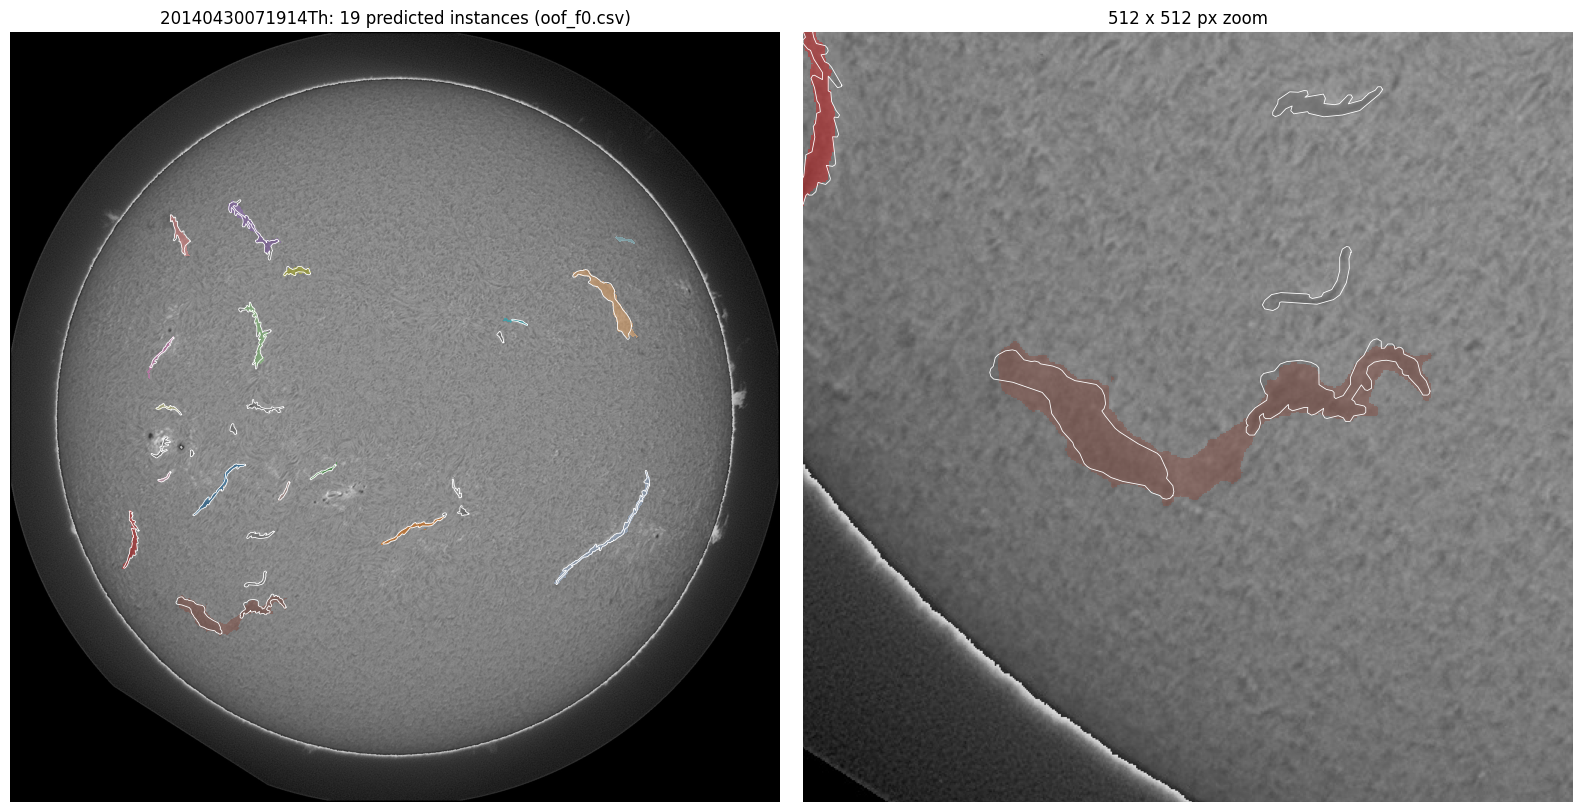

In [12]:
import pandas as pd

from filament.submission import rles_to_layers

source = OOF if OOF.exists() else SUBMISSION if SUBMISSION.exists() else None
if source is None:
    print("no predictions yet (run section 7 or 9)")
else:
    pred = pd.read_csv(source)
    pred["stem"] = pred.filament_id.str.rsplit("_", n=1).str[0]
    show = pred.stem.value_counts().index[0]  # the image with the most instances
    img_dir = data_root() / (TRAIN_IMAGES if source == OOF else TEST_IMAGES)
    img = load_image_gray(img_dir, show + ".jpeg")
    layers = rles_to_layers(pred[pred.stem == show].segmentation_rle.tolist())
    label = np.zeros(img.shape, np.int32)
    for k, layer in enumerate(layers, 1):
        label[layer > 0] = k
    ys, xs = np.nonzero(layers[int(np.argmax(layers.sum(axis=(1, 2))))])  # zoom on the largest instance
    x0, y0 = int(np.clip(xs.mean() - 256, 0, 1536)), int(np.clip(ys.mean() - 256, 0, 1536))
    fig, axes = plt.subplots(1, 2, figsize=(16, 8))
    for ax, (xa, xb, ya, yb) in zip(axes, [(0, 2048, 0, 2048), (x0, x0 + 512, y0, y0 + 512)]):
        ax.imshow(img, cmap="gray")
        ax.imshow(np.ma.masked_equal(label, 0), cmap="tab20", alpha=0.5, interpolation="nearest")
        for rec in by_stem.get(show, []):
            for f in rec.filaments:
                poly = np.array(f.polygon).reshape(-1, 2)
                ax.plot(*np.vstack([poly, poly[:1]]).T, color="white", lw=0.6)
        ax.set_xlim(xa, xb)
        ax.set_ylim(yb, ya)
        ax.axis("off")
    axes[0].set_title(f"{show}: {len(layers)} predicted instances ({source.name})")
    axes[1].set_title("512 x 512 px zoom")
    plt.tight_layout()
    plt.show()

## Notes

* Only the competition's training data and the test images are used.
* The selection model is fitted from `data/uhat_train.csv.gz`, built from the
  training images only.